# **Beyond the Scoreboard: IPL Data Analysis**
*Analyzing 17 seasons of IPL data (2008–2024) using Python for cleaning and PostgreSQL for analysis.*

### **1. Load the Data**

In [1]:
import pandas as pd

path = "/content/drive/MyDrive/IPL Datasets/"
matches = pd.read_csv(path + "matches.csv")
deliveries = pd.read_csv(path + "deliveries.csv")

print("Matches: ", matches.shape)
print("Deliveries: ", deliveries.shape)

Matches:  (1095, 20)
Deliveries:  (260920, 17)


### **2. Inspect the Data**

In [2]:
print(matches.columns.tolist())
print(deliveries.columns.tolist())
display(matches.head())
display(deliveries.head())

['id', 'season', 'city', 'date', 'match_type', 'player_of_match', 'venue', 'team1', 'team2', 'toss_winner', 'toss_decision', 'winner', 'result', 'result_margin', 'target_runs', 'target_overs', 'super_over', 'method', 'umpire1', 'umpire2']
['match_id', 'inning', 'batting_team', 'bowling_team', 'over', 'ball', 'batter', 'bowler', 'non_striker', 'batsman_runs', 'extra_runs', 'total_runs', 'extras_type', 'is_wicket', 'player_dismissed', 'dismissal_kind', 'fielder']


,id,season,city,date,match_type,player_of_match,venue,team1,team2,toss_winner,toss_decision,winner,result,result_margin,target_runs,target_overs,super_over,method,umpire1,umpire2
0,335982,2007/08,Bangalore,2008-04-18,League,BB McCullum,M Chinnaswamy Stadium,Royal Challengers Bangalore,Kolkata Knight Riders,Royal Challengers Bangalore,field,Kolkata Knight Riders,runs,140.0,223.0,20.0,N,NaN,Asad Rauf,RE Koertzen
1,335983,2007/08,Chandigarh,2008-04-19,League,MEK Hussey,"Punjab Cricket Association Stadium, Mohali",Kings XI Punjab,Chennai Super Kings,Chennai Super Kings,bat,Chennai Super Kings,runs,33.0,241.0,20.0,N,NaN,MR Benson,SL Shastri
2,335984,2007/08,Delhi,2008-04-19,League,MF Maharoof,Feroz Shah Kotla,Delhi Daredevils,Rajasthan Royals,Rajasthan Royals,bat,Delhi Daredevils,wickets,9.0,130.0,20.0,N,NaN,Aleem Dar,GA Pratapkumar
3,335985,2007/08,Mumbai,2008-04-20,League,MV Boucher,Wankhede Stadium,Mumbai Indians,Royal Challengers Bangalore,Mumbai Indians,bat,Royal Challengers Bangalore,wickets,5.0,166.0,20.0,N,NaN,SJ Davis,DJ Harper
4,335986,2007/08,Kolkata,2008-04-20,League,DJ Hussey,Eden Gardens,Kolkata Knight Riders,Deccan Chargers,Deccan Chargers,bat,Kolkata Knight Riders,wickets,5.0,111.0,20.0,N,NaN,BF Bowden,K Hariharan


,match_id,inning,batting_team,bowling_team,over,ball,batter,bowler,non_striker,batsman_runs,extra_runs,total_runs,extras_type,is_wicket,player_dismissed,dismissal_kind,fielder
0,335982,1,Kolkata Knight Riders,Royal Challengers Bangalore,0,1,SC Ganguly,P Kumar,BB McCullum,0,1,1,legbyes,0,NaN,NaN,NaN
1,335982,1,Kolkata Knight Riders,Royal Challengers Bangalore,0,2,BB McCullum,P Kumar,SC Ganguly,0,0,0,NaN,0,NaN,NaN,NaN
2,335982,1,Kolkata Knight Riders,Royal Challengers Bangalore,0,3,BB McCullum,P Kumar,SC Ganguly,0,1,1,wides,0,NaN,NaN,NaN
3,335982,1,Kolkata Knight Riders,Royal Challengers Bangalore,0,4,BB McCullum,P Kumar,SC Ganguly,0,0,0,NaN,0,NaN,NaN,NaN
4,335982,1,Kolkata Knight Riders,Royal Challengers Bangalore,0,5,BB McCullum,P Kumar,SC Ganguly,0,0,0,NaN,0,NaN,NaN,NaN


In [3]:
# Count of Missing Values In Each Column of Each Data Frame
print(matches.isnull().sum())
print(deliveries.isnull().sum())

id                    0
season                0
city                 51
date                  0
match_type            0
player_of_match       5
venue                 0
team1                 0
team2                 0
toss_winner           0
toss_decision         0
winner                5
result                0
result_margin        19
target_runs           3
target_overs          3
super_over            0
method             1074
umpire1               0
umpire2               0
dtype: int64
match_id                 0
inning                   0
batting_team             0
bowling_team             0
over                     0
ball                     0
batter                   0
bowler                   0
non_striker              0
batsman_runs             0
extra_runs               0
total_runs               0
extras_type         246795
is_wicket                0
player_dismissed    247970
dismissal_kind      247970
fielder             251566
dtype: int64


In [4]:
# Identifying Seasons & Teams
print(matches["season"].unique())
print(sorted(matches["team1"].unique()))

['2007/08' '2009' '2009/10' '2011' '2012' '2013' '2014' '2015' '2016'
 '2017' '2018' '2019' '2020/21' '2021' '2022' '2023' '2024']
['Chennai Super Kings', 'Deccan Chargers', 'Delhi Capitals', 'Delhi Daredevils', 'Gujarat Lions', 'Gujarat Titans', 'Kings XI Punjab', 'Kochi Tuskers Kerala', 'Kolkata Knight Riders', 'Lucknow Super Giants', 'Mumbai Indians', 'Pune Warriors', 'Punjab Kings', 'Rajasthan Royals', 'Rising Pune Supergiant', 'Rising Pune Supergiants', 'Royal Challengers Bangalore', 'Royal Challengers Bengaluru', 'Sunrisers Hyderabad']


### **3. Clean the Data**

In [5]:
# Verify if Each Season was Played Within a Single Calendar Year
original = pd.read_csv(path + "matches.csv")
original["year"] = pd.to_datetime(original["date"]).dt.year
original.groupby("season")["year"].unique()

,year
season,
2007/08,[2008]
2009,[2009]
2009/10,[2010]
2011,[2011]
2012,[2012]
2013,[2013]
2014,[2014]
2015,[2015]
2016,[2016]


In [6]:
# 1. Season: "2007/08" -> 2008
matches["season"] = pd.to_datetime(matches["date"]).dt.year

# 2. Standardize renamed franchises
team_fix = {
    "Delhi Daredevils": "Delhi Capitals",
    "Kings XI Punjab": "Punjab Kings",
    "Rising Pune Supergiants": "Rising Pune Supergiant",
    "Royal Challengers Bangalore": "Royal Challengers Bengaluru",
}
for col in ["team1", "team2", "toss_winner", "winner"]:
    matches[col] = matches[col].replace(team_fix)
for col in ["batting_team", "bowling_team"]:
    deliveries[col] = deliveries[col].replace(team_fix)

# 3. Fill missing city using the venue's most common city
city_map = matches.dropna(subset=["city"]).groupby("venue")["city"].agg(lambda x: x.mode()[0])
matches["city"] = matches["city"].fillna(matches["venue"].map(city_map))
print("City still missing:", matches["city"].isnull().sum())

# 4. Check duplicates
print("Duplicate matches:", matches.duplicated().sum())
print("Duplicate deliveries:", deliveries.duplicated().sum())

# 5. Remove super overs (innings 3 and 4)
print("Super over balls removed:", (deliveries["inning"] > 2).sum())
deliveries = deliveries[deliveries["inning"] <= 2]

print("No-result matches:", matches["winner"].isnull().sum())

City still missing: 0
Duplicate matches: 0
Duplicate deliveries: 0
Super over balls removed: 161
No-result matches: 5


In [8]:
# Verifying Cleaning Results
print("Seasons:", matches["season"].min(), "to", matches["season"].max())
print("Teams:", matches["team1"].nunique())

Seasons: 2008 to 2024
Teams: 15


In [10]:
print("Deliveries after cleaning:", deliveries.shape)

Deliveries after cleaning: (260759, 17)


### **4. Save the Clean Files & Get the Table Structure**

In [9]:
# Save the Clean Files back onto drive
matches.to_csv(path + "matches_clean.csv", index=False)
deliveries.to_csv(path + "deliveries_clean.csv", index=False)

# Auto-generate table Schema to load into PostgreSQL
print(pd.io.sql.get_schema(matches, "matches"))
print(pd.io.sql.get_schema(deliveries, "deliveries"))

CREATE TABLE "matches" (
"id" INTEGER,
  "season" INTEGER,
  "city" TEXT,
  "date" TEXT,
  "match_type" TEXT,
  "player_of_match" TEXT,
  "venue" TEXT,
  "team1" TEXT,
  "team2" TEXT,
  "toss_winner" TEXT,
  "toss_decision" TEXT,
  "winner" TEXT,
  "result" TEXT,
  "result_margin" REAL,
  "target_runs" REAL,
  "target_overs" REAL,
  "super_over" TEXT,
  "method" TEXT,
  "umpire1" TEXT,
  "umpire2" TEXT
)
CREATE TABLE "deliveries" (
"match_id" INTEGER,
  "inning" INTEGER,
  "batting_team" TEXT,
  "bowling_team" TEXT,
  "over" INTEGER,
  "ball" INTEGER,
  "batter" TEXT,
  "bowler" TEXT,
  "non_striker" TEXT,
  "batsman_runs" INTEGER,
  "extra_runs" INTEGER,
  "total_runs" INTEGER,
  "extras_type" TEXT,
  "is_wicket" INTEGER,
  "player_dismissed" TEXT,
  "dismissal_kind" TEXT,
  "fielder" TEXT
)


# **Data Cleaning Summary**

### ***Dataset Overview***

*Coverage: 17 IPL seasons (2008–2024), 15 franchises. Tables are linked by `matches.id = deliveries.match_id`.*

| Table | Rows | Columns | Description |
|---|---|---|---|
| matches | 1095 | 20 | One row per match: teams, toss, venue, winner, result |
| deliveries | 260920 → 260759 (after cleaning) | 17 | One row per ball: batter, bowler, runs, extras, wickets |

### ***Issues Found & Fixes Applied***
| Issue | Fix | Why it matters |
|---|---|---|
| Inconsistent season labels (e.g., "2007/08", "2009/10") | Derived season from match date | Every IPL season is played within one calendar year, so the year is a reliable season label (verified) |
| Same franchise under different names (e.g., DD → DC) | Merged 4 renamed teams: Delhi, Punjab, Bengaluru, Rising Pune | Prevents one team's history from being split across two names |
| Super overs stored as innings 3 & 4 | Removed 161 super-over deliveries | Super overs are tie-breakers, not normal play, and would distort run & economy stats |
| 51 missing cities | Filled 51 using the most common city for the same venue; 0 remain | Not used in analysis, filled for completeness |
| 5 no-result matches (missing winner) | Excluded from win-based analysis | Rain-affected matches have no winner to analyze |
| Duplicate rows | Checked: 0 found | Confirms no double-counting |

### ***Missing Values Kept As-Is (Structural, Not Errors)***
- `method`: only filled for rain-affected (D/L) matches
- `extras_type`: only filled when a ball was an extra
- `player_dismissed`, `dismissal_kind`, `fielder`: only filled when a wicket fell
- `result_margin`, `target_runs`: missing for ties and no-results

### ***Assumptions & Decisions***
- **Deccan Chargers and Sunrisers Hyderabad kept separate:** they are different franchises with different owners, despite both being from Hyderabad.
- **Pune Warriors and Rising Pune Supergiant kept separate:** different owners and eras (2011–13 vs 2016–17).
- **Raw data left untouched:** cleaned data saved as `matches_clean.csv` and `deliveries_clean.csv`.
- Column names lowercased for PostgreSQL compatibility.

# **Visualizing Insights**

The query results used for visualization were exported from PostgreSQL.

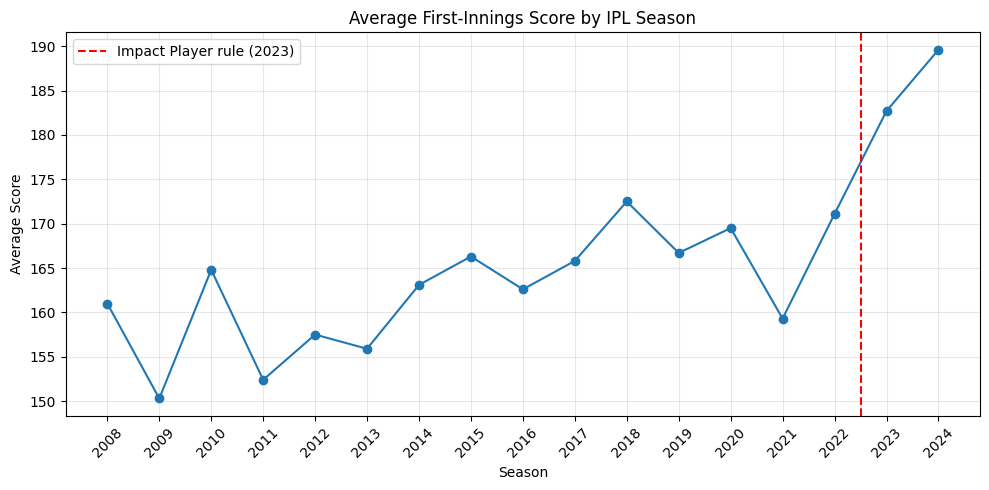

In [24]:
import matplotlib.pyplot as plt

# Chart 1: Scoring trend
trend = pd.read_csv(path + "q4_scoring_trend.csv")

plt.figure(figsize=(10, 5))
plt.plot(trend["season"], trend["avg_first_innings_score"], marker="o")
plt.axvline(x=2022.5, color="red", linestyle="--", label="Impact Player rule (2023)")
plt.title("Average First-Innings Score by IPL Season")
plt.xlabel("Season")
plt.ylabel("Average Score")
plt.xticks(trend["season"], rotation=45)
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(path + "scoring_trend.png", dpi=150, bbox_inches="tight")
plt.show()

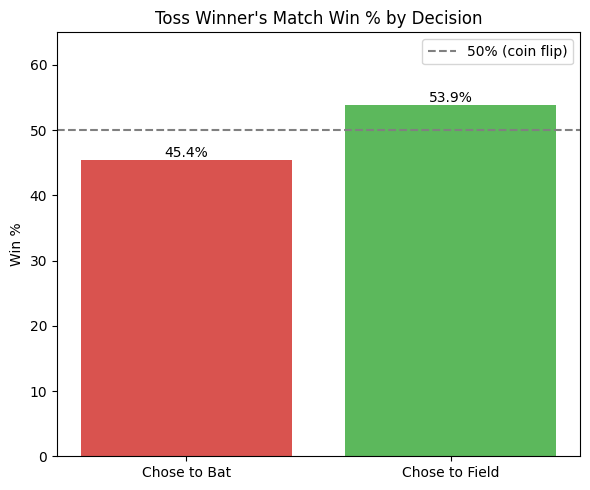

In [25]:
# Chart 2: The Toss Decision
plt.figure(figsize=(6, 5))
bars = plt.bar(["Chose to Bat", "Chose to Field"], [45.38, 53.86], color=["#d9534f", "#5cb85c"])
plt.axhline(y=50, color="gray", linestyle="--", label="50% (coin flip)")
plt.bar_label(bars, fmt="%.1f%%")
plt.title("Toss Winner's Match Win % by Decision")
plt.ylabel("Win %")
plt.ylim(0, 65)
plt.legend()
plt.tight_layout()
plt.savefig(path + "toss_decision.png", dpi=150, bbox_inches="tight")
plt.show()

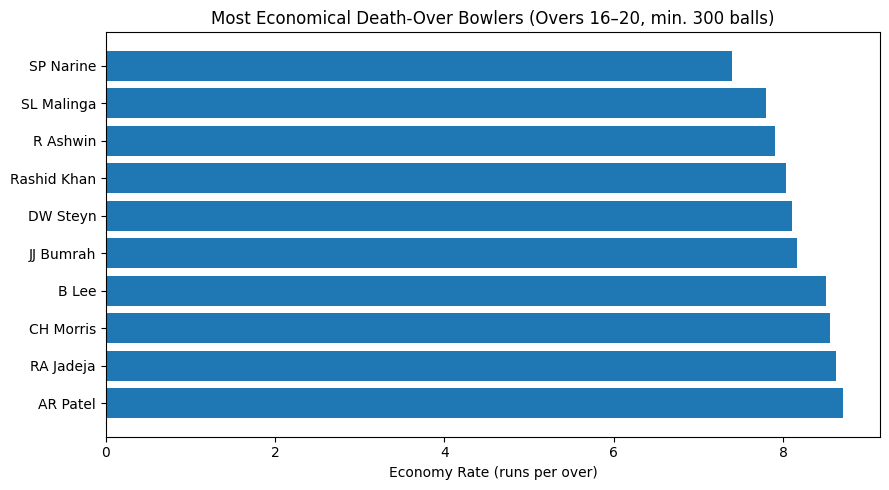

In [27]:
# Chart 3: Best death-over bowlers
bowlers = pd.read_csv(path + "q3_death_bowlers.csv").sort_values("economy", ascending=False)

plt.figure(figsize=(9, 5))
plt.barh(bowlers["bowler"], bowlers["economy"])
plt.title("Most Economical Death-Over Bowlers (Overs 16–20, min. 300 balls)")
plt.xlabel("Economy Rate (runs per over)")
plt.tight_layout()
plt.savefig(path + "death_over_bowlers.png", dpi=150, bbox_inches="tight")
plt.show()

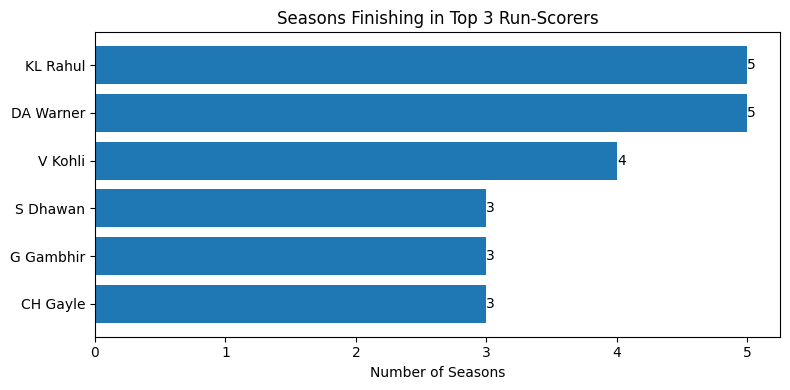

In [28]:
# Chart 4: Most Consistent Batters
plt.figure(figsize=(8, 4))
names = ["KL Rahul", "DA Warner", "V Kohli", "S Dhawan", "G Gambhir", "CH Gayle"]
counts = [5, 5, 4, 3, 3, 3]
bars = plt.barh(names[::-1], counts[::-1])
plt.bar_label(bars)
plt.title("Seasons Finishing in Top 3 Run-Scorers")
plt.xlabel("Number of Seasons")
plt.tight_layout()
plt.savefig(path + "consistent_batters.png", dpi=150, bbox_inches="tight")
plt.show()